# Cuándo comprar evidencia antes de escalar IA

## Resumen
Caso sintético: el mejor candidato es un piloto de 50 observaciones con valor esperado neto 5.140,42 unidades frente a 0 al decidir hoy. El piloto fijo de 100 obtiene 5.138,22: la diferencia de diseño es pequeña, no una ventaja comercial demostrada.

## Contexto y método
Sea $p\sim Beta(a,b)$ la probabilidad desconocida de éxito operativo de una tarea. No es uplift causal. La utilidad de escalar es $U(p)=N(vp-c)-F$ y detener vale cero. Un piloto IID $K\mid p\sim Bin(n,p)$ actualiza a $Beta(a+K,b+n-K)$.

$EVSI(n)=\sum_k P(K=k)\max(0,U(E[p\mid k]))-\max(0,U(E[p]))$. El valor neto resta el costo fijo y variable del piloto. Se enumera un conjunto finito, no se afirma óptimo global.

### Supuestos clave
Una etapa, neutralidad al riesgo, población futura fija separada del piloto, costos y valor por éxito conocidos; no descuento, drift, externalidades ni efectos de red. El piloto no genera beneficios contabilizados. La decisión usa solo su resultado, nunca el p latente.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from src.evsi import Case, choose, evaluate
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'seed': 20261023,
 'alpha': 6.0,
 'beta': 4.0,
 'population': 10000,
 'benefit': 10.0,
 'unit_cost': 6.0,
 'fixed_rollout': 0.0,
 'experiment_fixed': 100.0,
 'experiment_unit': 5.0,
 'sizes': [0, 10, 25, 50, 100, 200, 500, 1000],
 'mc_replicates': 200000,
 'hypothesis_min_increment': 1000,
 'units': 'synthetic monetary units; fixed future deployment population, study budget separate'}

## Resultados: baseline y tamaño de piloto
Todos los valores son expectativas bajo el prior sintético; no ingresos observados.

,n,evsi,experiment_cost,net_value,immediate_value,increment
0,0,0.000,0.0,0.000,0.0,0.000
1,10,4201.000,150.0,4051.000,0.0,4051.000
2,25,5072.303,225.0,4847.303,0.0,4847.303
3,50,5490.418,350.0,5140.418,0.0,5140.418
4,100,5738.224,600.0,5138.224,0.0,5138.224
5,200,5874.299,1100.0,4774.299,0.0,4774.299
6,500,5960.373,2600.0,3360.373,0.0,3360.373
7,1000,5989.853,5100.0,889.853,0.0,889.853


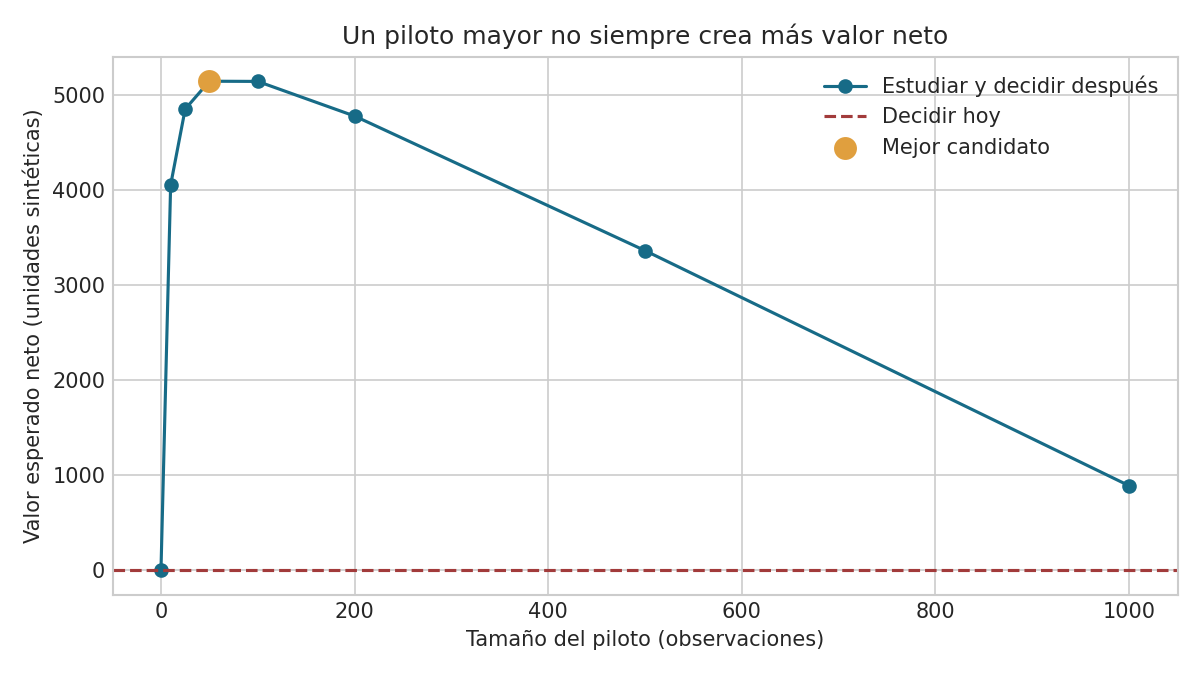

In [2]:
designs=pd.read_csv('results/designs.csv')
display(designs.round(3))
display(Image(filename='results/decision_curve.png'))

## Validación independiente por simulación
200.000 réplicas generan p y luego K, aplican la política a K y evalúan utilidad al p verdadero. El error estándar mide ruido MC bajo el modelo, no incertidumbre de negocio.

In [3]:
display({k:summary[k] for k in ['selected','evpi','mc_mean','mc_standard_error']})
assert abs(summary['mc_mean']-summary['selected']['net_value']) < 5*summary['mc_standard_error']
assert 0<=summary['selected']['evsi']<=summary['evpi']
assert summary['selected']['increment']>=cfg['hypothesis_min_increment']

{'selected': {'n': 50,
  'evsi': 5490.41839524532,
  'experiment_cost': 350.0,
  'net_value': 5140.41839524532,
  'immediate_value': 0.0,
  'increment': 5140.41839524532,
  'action': 'experimentar'},
 'evpi': 6019.743743999996,
 'mc_mean': 5153.613560613619,
 'mc_standard_error': 18.87000190645772}

## Sensibilidad y decisiones
Experimentar si el mejor valor neto supera decidir hoy. Escalar si la mejor opción sin estudio tiene utilidad positiva; detener en otro caso. Ajustar/rediseñar: variar costos, prior, horizonte y métricas si el piloto no es transferible. Esta herramienta no identifica efectos causales.

In [4]:
display(pd.read_csv('results/sensitivity.csv').round(3))

,prior_multiplier,study_unit_cost,n,evsi,experiment_cost,net_value,immediate_value,increment,action
0,1,0.0,1000,5989.853,100.0,5889.853,0.0,5889.853,experimentar
1,1,5.0,50,5490.418,350.0,5140.418,0.0,5140.418,experimentar
2,1,25.0,25,5072.303,725.0,4347.303,0.0,4347.303,experimentar
3,1,100.0,10,4201.000,1100.0,3101.000,0.0,3101.000,experimentar
4,5,0.0,1000,2683.111,100.0,2583.111,0.0,2583.111,experimentar
5,5,5.0,100,2242.906,600.0,1642.906,0.0,1642.906,experimentar
6,5,25.0,25,1576.244,725.0,851.244,0.0,851.244,experimentar
7,5,100.0,0,0.000,0.0,0.000,0.0,0.000,detener
8,20,0.0,1000,1259.847,100.0,1159.847,0.0,1159.847,experimentar
9,20,5.0,50,614.623,350.0,264.623,0.0,264.623,experimentar


## Conclusiones y límites
La información gratuita no empeora valor esperado; información costosa puede destruirlo. El n=100 casi empata n=50; no sobredimensionar esa diferencia. No se valida un producto IA real. La innovación es integrar un gate exacto auditable en un programa ejecutivo S1, no inventar EVSI. Referencias, fallos y rúbrica están en informe.md y referencias.bib.